# Forest Cover Type Prediction

**Project Link:** [Kaggle: Forest Cover Type Prediction](https://www.kaggle.com/competitions/forest-cover-type-prediction)

**Challenge Description:**
The objective is to predict the predominant forest cover type (the most common tree species) for 30x30 meter geographic cells located in the Roosevelt National Forest of northern Colorado. The predictions must be made using strictly cartographic variables, such as elevation, slope, and distance to water or roads, rather than remotely sensed satellite imagery.

**Data Description:**
The training dataset contains 15,120 observations and 56 columns. The features represent cartographic data, including 10 continuous numerical variables (elevation, slope, hillshade, distances) and 44 binary categorical variables (4 one-hot encoded wilderness areas and 40 one-hot encoded soil types). The target variable is an integer from 1 to 7 representing the specific forest cover type.

In [1]:
# !kaggle competitions download forest-cover-type-prediction -p data --unzip
# !ls -lh data 

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/train.csv')

num_rows, num_features = df.shape
print(f"Rows (Data Points): {num_rows:,}")
print(f"Features (including Id and Target): {num_features}")
print(f"Missing values: {np.any(df.isnull())}")

target_col = 'Cover_Type'
print(f"\nTarget Variable: {target_col}")
print("Class Distribution:")
print(df[target_col].value_counts().sort_index())

Rows (Data Points): 15,120
Features (including Id and Target): 56
Missing values: False

Target Variable: Cover_Type
Class Distribution:
Cover_Type
1    2160
2    2160
3    2160
4    2160
5    2160
6    2160
7    2160
Name: count, dtype: int64


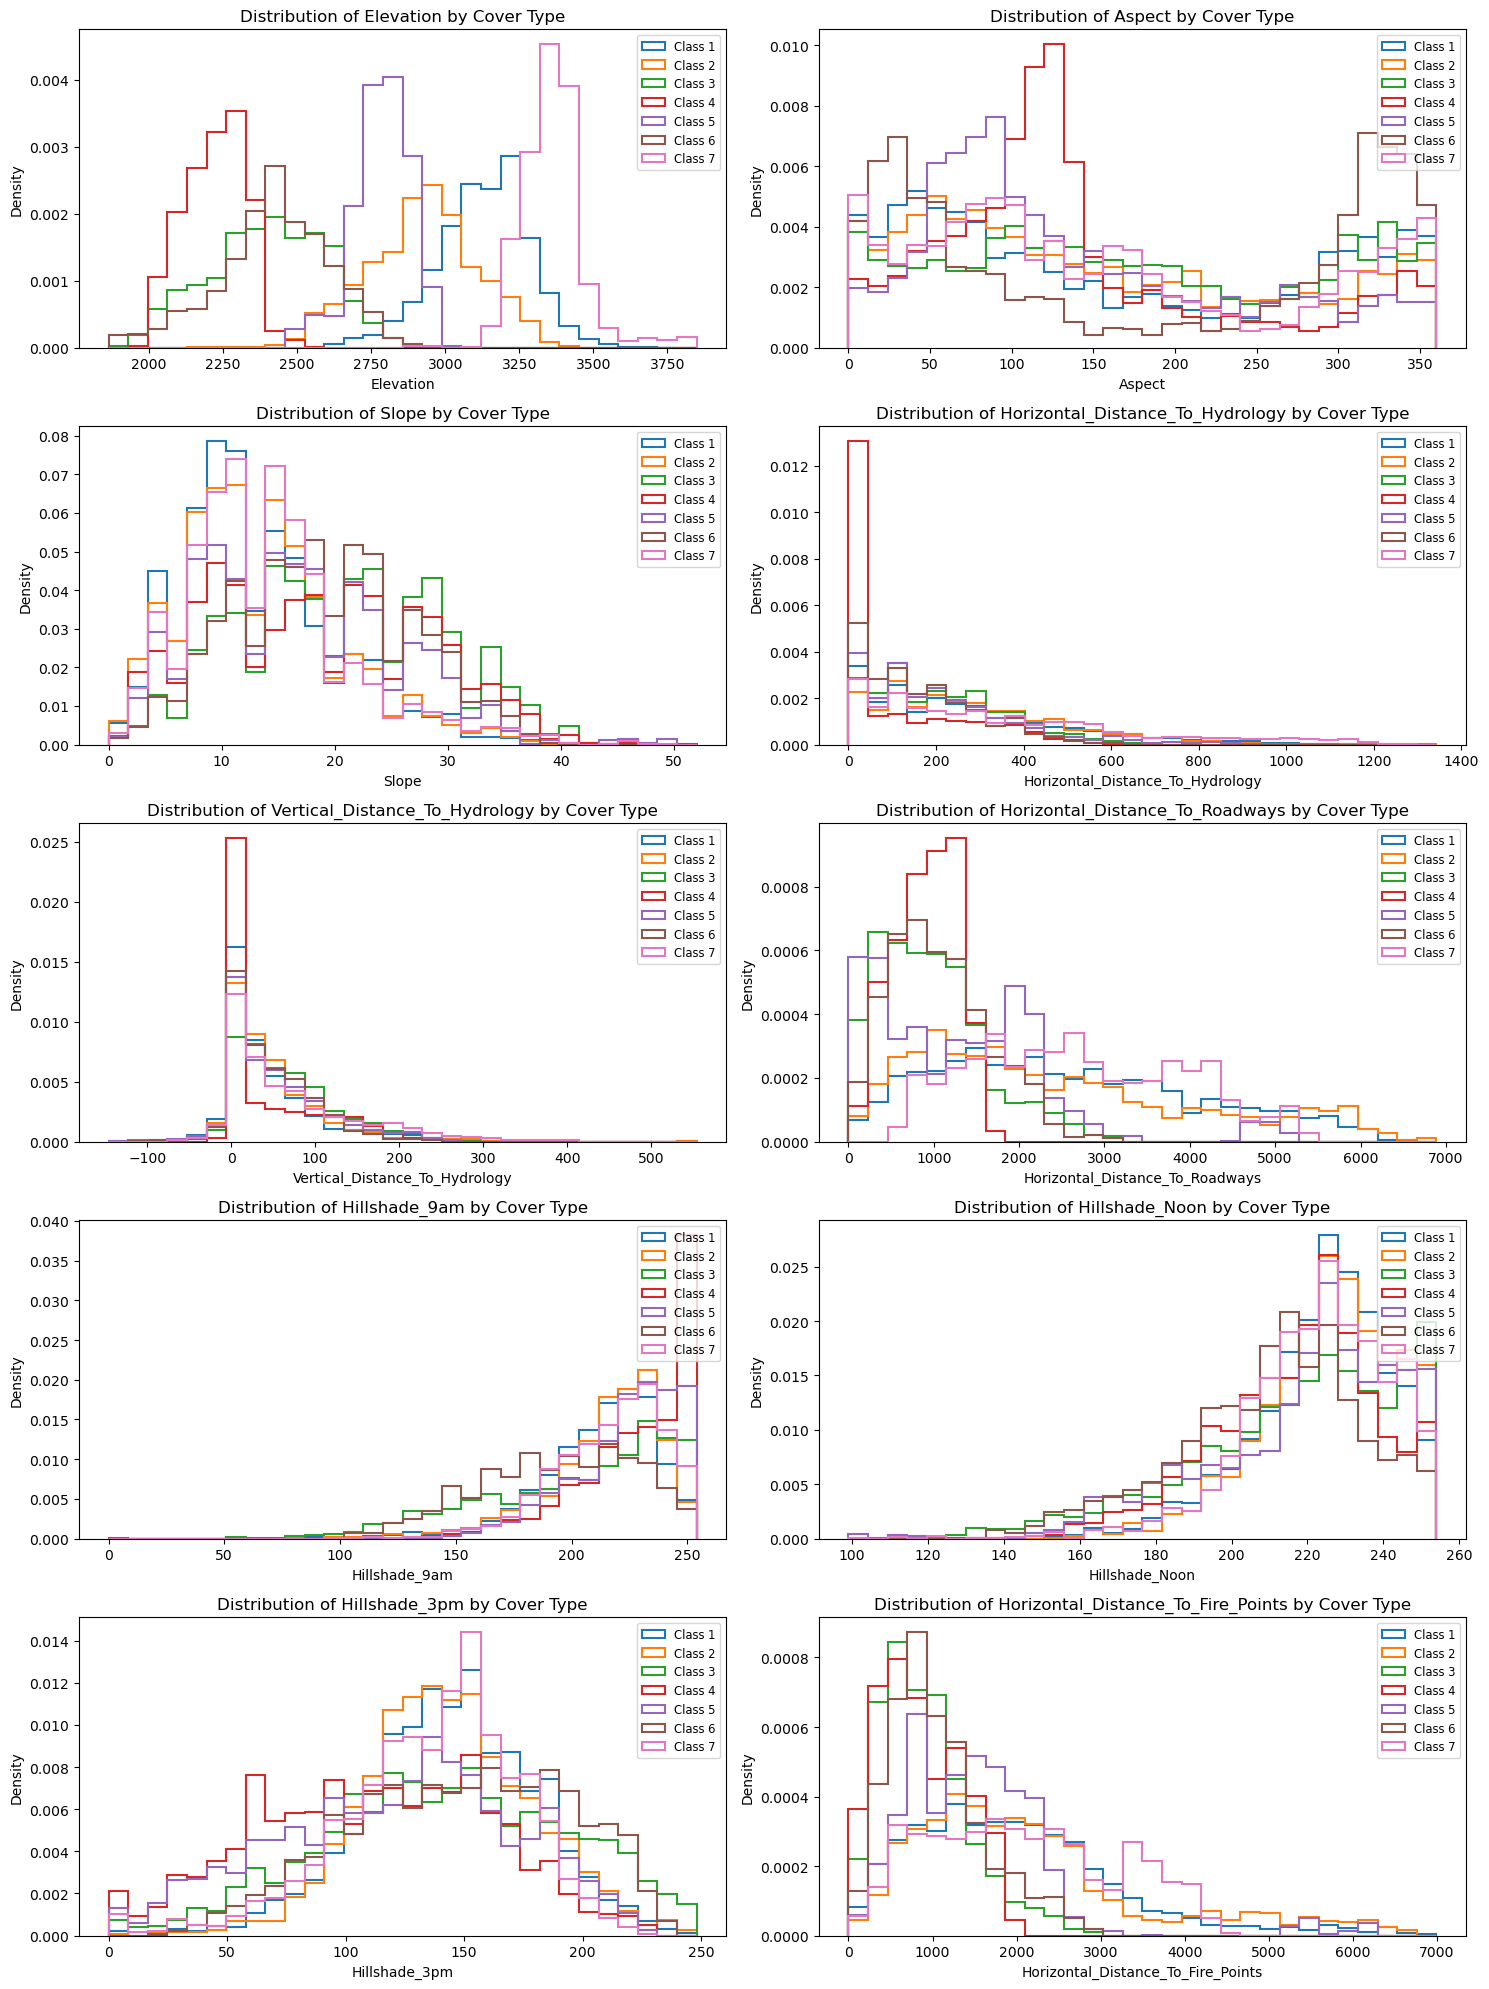

In [3]:
import matplotlib.pyplot as plt

df = pd.read_csv('data/train.csv')

# excluding Id and onehot categories
num_cols = [
    "Elevation", "Aspect", "Slope",
    "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways", "Hillshade_9am",
    "Hillshade_Noon", "Hillshade_3pm", "Horizontal_Distance_To_Fire_Points"
]

target = 'Cover_Type'
classes = df[target].unique()
classes.sort()

# normalized step histograms for every numerical feature
plt.figure(figsize=(15, 20))
for i, col in enumerate(num_cols, 1):
    plt.subplot(5, 2, i)
    
    # global bin edges for this feature so all classes align
    _, edges = np.histogram(df[col].dropna(), bins=30)
    
    for cls in classes:
        subset = df[df[target] == cls]
        plt.hist(subset[col], bins=edges, density=True, histtype="step", linewidth=1.5, label=f"Class {cls}")
        
    plt.title(f"Distribution of {col} by Cover Type")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.legend(loc='upper right', fontsize='small')

plt.tight_layout()
plt.show()

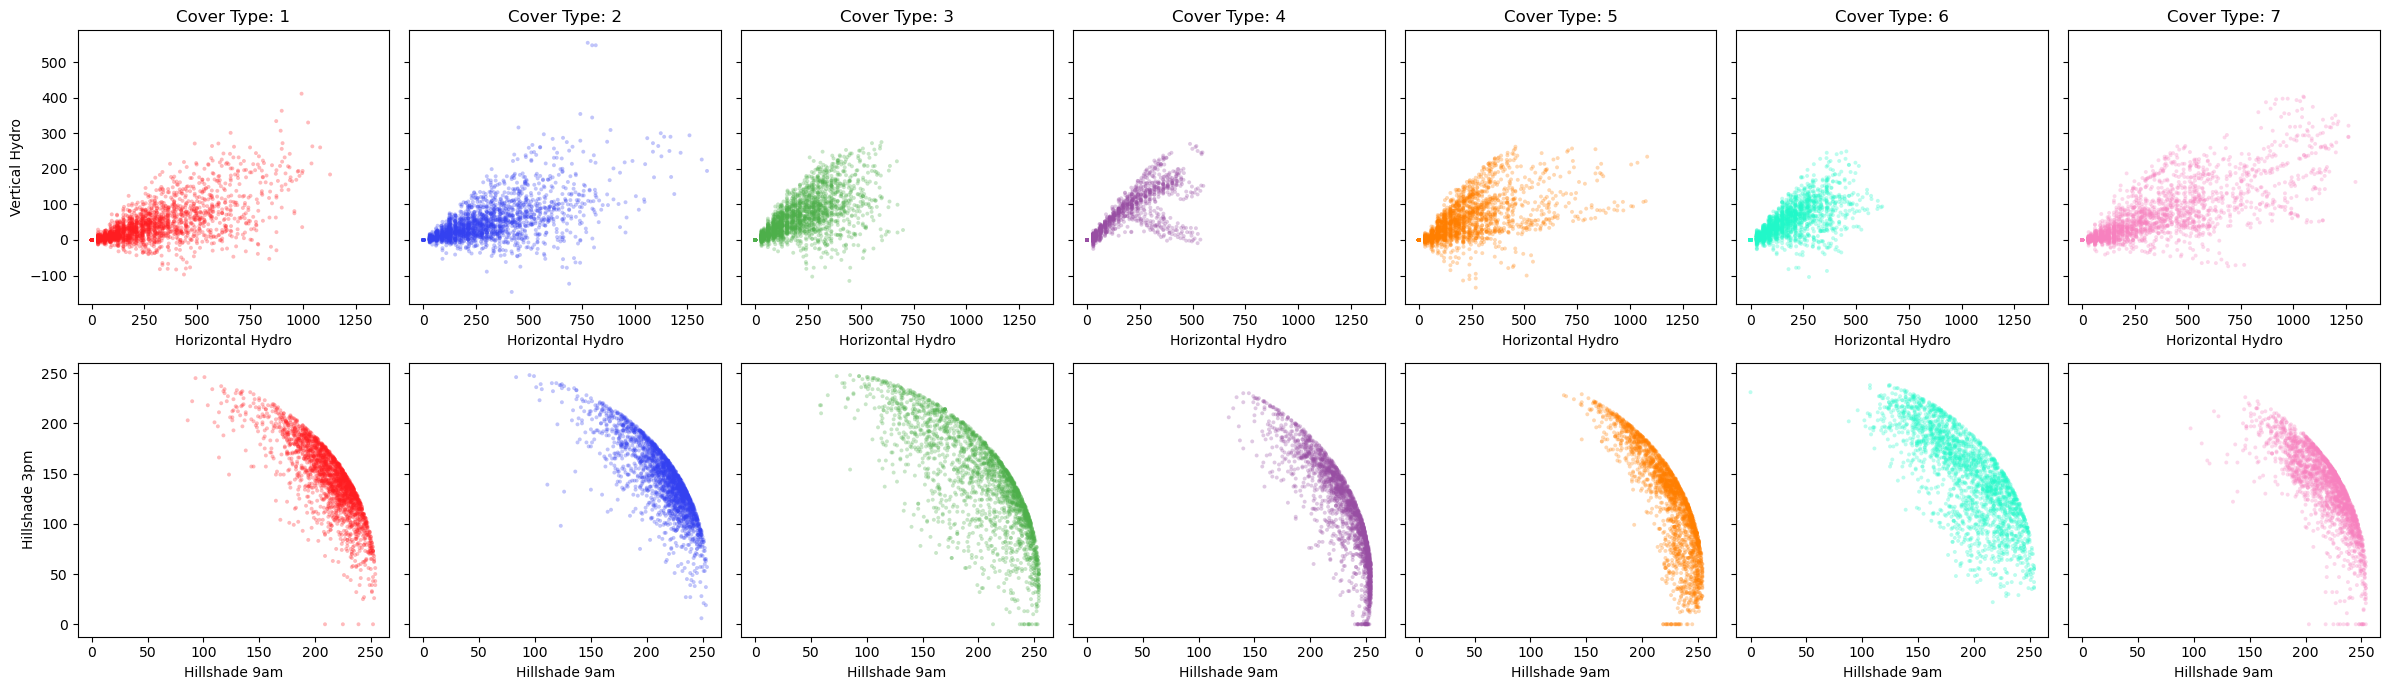

In [4]:
import matplotlib.pyplot as plt

classes = df['Cover_Type'].unique()
classes.sort()

colors = ["#ff1d21", "#3441f0", '#4daf4a', '#984ea3', '#ff7f00', "#21f8c9", '#f781bf']

fig, axes = plt.subplots(2, 7, figsize=(24, 7), sharex='row', sharey='row')

for i, cls in enumerate(classes):
    subset = df[df['Cover_Type'] == cls]
    
    axes[0, i].scatter(subset['Horizontal_Distance_To_Hydrology'], subset['Vertical_Distance_To_Hydrology'], alpha=0.3, s=8, edgecolors='none', color=colors[i])
    axes[0, i].set_title(f'Cover Type: {cls}')
    axes[0, i].set_xlabel('Horizontal Hydro')
    if i == 0:axes[0, i].set_ylabel('Vertical Hydro')
        
    axes[1, i].scatter(subset['Hillshade_9am'], subset['Hillshade_3pm'], alpha=0.3, s=8, edgecolors='none', color=colors[i])
    axes[1, i].set_xlabel('Hillshade 9am')
    if i == 0:axes[1, i].set_ylabel('Hillshade 3pm')

plt.tight_layout()
plt.show()

### Numerical Features Observations:
- Elevation is the most telling feature. The histograms show clear peaks for almost every class (Class 7 is completely isolated on the high end, Class 4 on the low end).
- Horizontal_Distance_To_Roadways & Horizontal_Distance_To_Fire_Points also show decent separation. For example, Class 1 and Class 7 have much flatter distributions (they exist further from roads/fire points) compared to Class 3 and 4, which spike near zero.
- Hillshade features much less discriminative. The shapes of the distributions are nearly identical across all 7 classes, meaning they provide less unique signal.

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/train.csv')

# drop id and empty soils
cols_to_drop = ['Id', 'Soil_Type7', 'Soil_Type15']
df_clean = df.drop(columns=cols_to_drop)

# combine horizontal and vertical water distances
df_clean['Euclidean_Distance_To_Hydrology'] = np.sqrt(
    df_clean['Horizontal_Distance_To_Hydrology']**2 + 
    df_clean['Vertical_Distance_To_Hydrology']**2)

# convert 360 degree to sin and cos because the model will treat 0 and 360 as far apart but they are actually the same direction
df_clean['Aspect_sin'] = np.sin(df_clean['Aspect'] * np.pi / 180)
df_clean['Aspect_cos'] = np.cos(df_clean['Aspect'] * np.pi / 180)
df_clean = df_clean.drop(columns=['Aspect']) # drop degree column after conversion

# xgboost needs classes to start at 0
target = 'Cover_Type'
df_clean[target] = df_clean[target] - 1

X = df_clean.drop(columns=[target])
y = df_clean[target]

# split into 60% Train, 20% Validation, 20% Test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

In [ ]:
import xgboost as xgb
from sklearn.metrics import accuracy_score

# tree_method='hist' speeds up training for tabular data
model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# evaluate on sample
val_predictions = model.predict(X_val)
val_accuracy = accuracy_score(y_val, val_predictions)
print(f"Validation Accuracy: {val_accuracy:.4f}")

# load official test set
df_test = pd.read_csv('data/test.csv')

# save the Id column for the submission file then drop it from features
test_ids = df_test['Id']
X_kaggle = df_test.drop(columns=['Id', 'Soil_Type7', 'Soil_Type15'])

# apply the exact same adjustments to the Kaggle test set
X_kaggle['Euclidean_Distance_To_Hydrology'] = np.sqrt(
    X_kaggle['Horizontal_Distance_To_Hydrology']**2 + 
    X_kaggle['Vertical_Distance_To_Hydrology']**2
)

X_kaggle['Aspect_sin'] = np.sin(X_kaggle['Aspect'] * np.pi / 180)
X_kaggle['Aspect_cos'] = np.cos(X_kaggle['Aspect'] * np.pi / 180)
X_kaggle = X_kaggle.drop(columns=['Aspect'])

kaggle_predictions = model.predict(X_kaggle)

# shift predictions back up by 1 (since zero indexed the training target for XGBoost)
final_predictions = kaggle_predictions + 1

submission = pd.DataFrame({
    'Id': test_ids,
    'Cover_Type': final_predictions
})
submission.to_csv('submission.csv', index=False)
print("saved 'submission.csv'")

Validation Accuracy: 0.8049
Submission saved to 'submission.csv'
